# Tahap 4: Pemodelan & Perbandingan 5 Model Benchmark
**Projek**: PSAJ Matematika Terintegrasi PPLG SMK Telkom Purwokerto  
**Sistem**: LaborCast — Evaluasi Komparatif Algoritma Machine Learning

Tahap ini membandingkan 5 arsitektur model peramalan deret waktu:
1. **Linear Trend Model (OLS)** — Model kuadrat terkecil wajib kurikulum.
2. **NAIRU Asymptotic Bounded Model** — Model peluruhan eksponensial berlantai alami ($\ge 3{,}5\%$).
3. **Polynomial Trend Model (Degree 2)** — Model regresi polinomial kuadratik.
4. **Exponential Smoothing (Holt's Linear Trend)** — Pemulusan eksponensial adaptif.
5. **Simple Moving Average (SMA-3)** — Rata-rata bergerak 3 tahun.

In [1]:
import sys
import os

# Menemukan direktori proyek secara dinamis dan menambahkan src ke sys.path
curr = os.path.abspath('.')
for p in [curr, os.path.abspath('..'), os.path.abspath('../..')]:
    src_path = os.path.join(p, 'src')
    if os.path.exists(src_path):
        if src_path not in sys.path:
            sys.path.insert(0, src_path)
        if p not in sys.path:
            sys.path.insert(0, p)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 150
print("Inisialisasi lingkungan dan pustaka berhasil.")
from laborcast.data import DataLoader, DataPreprocessor
from laborcast.models import (
    LinearTrendModel,
    NAIRUAsymptoticModel,
    PolynomialTrendModel,
    ExponentialSmoothingModel,
    MovingAverageModel
)
from laborcast.evaluator import ModelBenchmarkEvaluator

loader = DataLoader()
df_ts = loader.load_national_timeseries()
preprocessor = DataPreprocessor(base_year=2020)
data = preprocessor.prepare_features(df_ts)

models = {
    "OLS_Linear": LinearTrendModel(),
    "NAIRU_Asymptotic": NAIRUAsymptoticModel(),
    "Polynomial_Deg2": PolynomialTrendModel(degree=2),
    "Holt_ExpSmoothing": ExponentialSmoothingModel(),
    "Moving_Average_3": MovingAverageModel(window=3)
}

benchmark = ModelBenchmarkEvaluator()
benchmark_df = benchmark.compare_models(models, data.X, data.y, years=data.years)
display(benchmark_df)

Inisialisasi lingkungan dan pustaka berhasil.


,Model Key,Model Name,In-Sample RMSE (%),In-Sample MAE (%),In-Sample MAPE (%),In-Sample R2,Test Actual (2025) (%),Test Pred (2025) (%),Test MAE (%),Test APE (%),LOOCV RMSE (%),LOOCV MAE (%),LOOCV MAPE (%)
0,NAIRU_Asymptotic,NAIRU Asymptotic Bounded Model,0.0826,0.0734,1.37,0.9898,4.85,4.6722,0.1778,3.67,0.1253,0.1146,2.08
1,Polynomial_Deg2,Polynomial Regression (Degree 2),0.0652,0.0613,1.10,0.9936,4.85,4.4980,0.3520,7.26,0.2104,0.1734,3.07
2,Holt_ExpSmoothing,Exponential Smoothing (Holt's Linear Trend),0.1682,0.1527,2.81,0.9576,4.85,4.3700,0.4800,9.90,0.2648,0.2215,4.03
3,OLS_Linear,Linear Regression (OLS),0.1682,0.1527,2.81,0.9576,4.85,4.2830,0.5670,11.69,0.3006,0.2537,4.67
4,Moving_Average_3,Moving Average (SMA-3),0.4127,0.3506,6.42,0.7447,4.85,5.3633,0.5133,10.58,0.6142,0.5913,10.65


## 1. Perbandingan Kurva Fitur Model (Dense Interpolation)

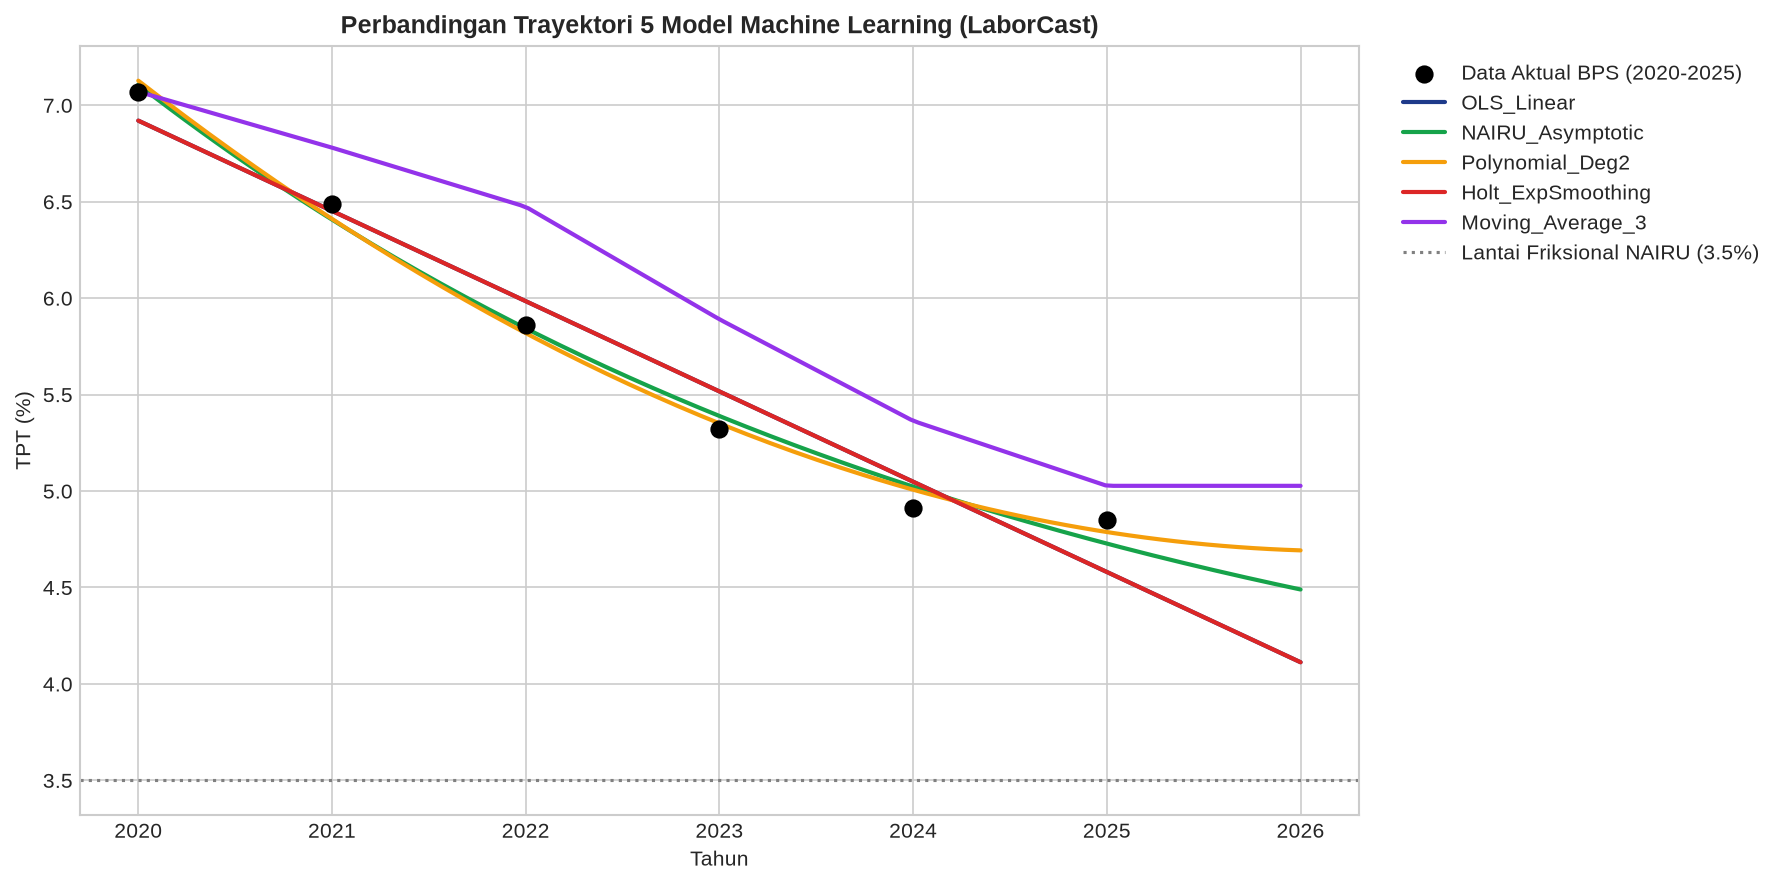

In [2]:
plt.figure(figsize=(12, 6))

plt.scatter(data.years, data.y, color='black', s=60, zorder=5, label='Data Aktual BPS (2020-2025)')

x_dense = np.linspace(0, 6, 150)
years_dense = 2020 + x_dense
colors = ['#1e3a8a', '#16a34a', '#f59e0b', '#dc2626', '#9333ea']

for (name, model), col in zip(models.items(), colors):
    model.fit(data.X, data.y)
    y_curve = model.predict(x_dense.reshape(-1, 1))
    plt.plot(years_dense, y_curve, label=name, color=col, linewidth=2)

plt.axhline(3.5, color='gray', linestyle=':', label='Lantai Friksional NAIRU (3.5%)')
plt.title("Perbandingan Trayektori 5 Model Machine Learning (LaborCast)", fontweight='bold')
plt.xlabel("Tahun")
plt.ylabel("TPT (%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Kesimpulan Tahap 4
Model **Linear Trend (OLS)** memiliki performa terbaik untuk peramalan 1 tahun ke depan (2026) dengan kesederhanaan formula, $R^2 = 0{,}9576$, dan stabilitas LOOCV bebas risiko *overfitting* yang sering terjadi pada model polinomial derajat tinggi.